# Questão 2 — Extração de argumentos de sentenças: demonstração

Python 3.14, `pymupdf`, `numpy`, `scipy`, `pydantic`, `matplotlib` (versões em `requirements.txt`). O código da solução está em `q2.py`; este caderno só executa as demonstrações. Rodar com *Restart & Run All*.

As sentenças são sintéticas, geradas em PDF com gabarito (seeds fixas). O LLM é simulado: responde às mesmas requisições que o cliente real recebe e erra com taxas definidas em `PerfilSimulado`. Essas taxas não medem nenhum modelo; servem para exercitar cada controle. Os números de qualidade deste caderno mostram que o mecanismo funciona, não a qualidade de um modelo real, que se mede no conjunto de referência anotado (seção 5 do `questao2.md`). A seção 12 roda a parte determinística, sem LLM, sobre 226 sentenças reais do TJSP (`sentencas_tjsp.json`): são os únicos números deste caderno medidos em texto real.

In [1]:
import json
import sys

sys.dont_write_bytecode = True   # sem __pycache__ ao lado dos entregáveis
from dataclasses import replace

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pydantic
import pymupdf
import scipy

from q2 import *

print(f"Python {sys.version.split()[0]} | pymupdf {pymupdf.__version__} | numpy {np.__version__} | scipy {scipy.__version__} | pydantic {pydantic.__version__}")
VERSAO_ATIVA, PARTES_VERSAO = versao_extracao("perfil=ativa")
print("versão de extração:", VERSAO_ATIVA, json.dumps(PARTES_VERSAO, ensure_ascii=False))

Python 3.14.6 | pymupdf 1.28.2 | numpy 2.5.4 | scipy 1.18.1 | pydantic 2.14.1
versão de extração: ext_9884d198c5 {"prompts": {"mapa": "18703db37fbb", "extrator": "910345a922e9", "verificador": "c7fcb10469b1", "verificador_forte": "c7fcb10469b1", "fatos": "2283d1bc4b40", "dispositivo": "d3dbed518ca9", "resultado": "77bbe7b863f8"}, "modelos": ["claude-haiku-5-5", "claude-sonnet-5-5", "claude-haiku-5-5", "claude-sonnet-5-5", "MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7", "BAAI/bge-m3@5617a9f"], "schema": "2.1.0", "codigo": "251985230950", "parametros": "f2b854a93c45", "regex": "ee28f547fc1f", "extra": "perfil=ativa"}


## 1. Uma sentença, do PDF aos parágrafos numerados

*Afirmação:* Antes de qualquer LLM, o código divide a sentença em parágrafos `§1…§n` com página e offsets, separa relatório, fundamentação e dispositivo, marca os tópicos do juiz e marca as citações (recuo, aspas, marcador, formato de ementa). Citação depois de "adoto como razões de decidir" é marcada como adotada.

In [2]:
pdf, gab = gerar_sentenca(7, area="negativacao", juizado=False, titulos=True, preliminar=True, preexistente=False,
                          relationem=True, obiter=True, relato=True, ocr=True)
sent = ler_pdf(gab.sentenca_id, pdf)
marcar_citacoes(sent)
regex = fronteiras_regex(sent)
segmentar(sent, {k: regex[k] for k in ("fundamentacao", "dispositivo")})
print(f"{gab.sentenca_id}: {pymupdf.open(stream=pdf).page_count} páginas, {len(sent.paragrafos)} parágrafos, texto_hash {sent.texto_hash}")
print(f"fronteiras pela regex: fundamentação §{regex['fundamentacao']}, dispositivo §{regex['dispositivo']} | gabarito: {gab.fronteiras}\n")
for p in sent.paragrafos:
    marca = "citação adotada" if p.adotado else ("citação" if p.e_citacao else ("título" if p.titulo else ""))
    print(f"§{p.indice:<3} pág.{p.pagina} {p.secao:<14} {p.topico[:26]:<27} {marca:<16} {p.texto[:70]}")
assert {"fundamentacao": regex["fundamentacao"], "dispositivo": regex["dispositivo"]} == gab.fronteiras
adotados = [p.indice for p in sent.paragrafos if p.adotado]
assert adotados == [a.paragrafo for a in gab.argumentos if a.id == "dm"], "o bloco per relationem é o argumento de dano moral"
print("\ntópicos (unidade de extração):", [(t["id"], t["titulo"], t["paragrafos"]) for t in topicos(sent)])

sent_0007: 3 páginas, 33 parágrafos, texto_hash 7480fb7eff545d8e
fronteiras pela regex: fundamentação §14, dispositivo §28 | gabarito: {'fundamentacao': 14, 'dispositivo': 28}

§1   pág.1 cabecalho                                                   PODER JUDICIÁRIO
§2   pág.1 cabecalho                                                   TRIBUNAL DE JUSTIÇA DO ESTADO DE SÃO PAULO
§3   pág.1 cabecalho                                                   1ª Vara Cível da Comarca de Ribeirão Preto
§4   pág.1 cabecalho                                                   Processo nº 2171979-40.2024.8.26.0565
§5   pág.1 cabecalho                                                   Requerente: Helena Rodrigues - Requerido: Banco Vértice S.A.
§6   pág.1 cabecalho                                                   SENTENÇA
§7   pág.1 relatorio                                                   Vistos.
§8   pág.1 relatorio                                                   RELATÓRIO
§9   pág.1 relatorio      

## 2. Saída estruturada

*Afirmação:* O modelo devolve uma ferramenta obrigatória com JSON Schema estrito (gerado do Pydantic): enums fechados, nenhum campo fora do schema. Limites de tamanho não vão na decodificação; o Pydantic confere na volta. Prompts e schema têm hash, que entra na versão.

In [3]:
schema = schema_para_api(RespostaExtrator)
arg_schema = schema["$defs"]["ArgumentoCandidato"]
print("campos obrigatórios do candidato:", arg_schema["required"])
print("tipos:", schema["$defs"]["Tipo"]["enum"])
assert arg_schema["additionalProperties"] is False
print("hash dos prompts:", versao_prompts())
try:
    ArgumentoCandidato(questao="q", tese="x", resumo="y", tipo="jurisprudencia", por_que_papel="z", papel="ratio_decidendi", pedidos=["P1"], conclusao="acolhe",
                       favorece="autor", paragrafos=[3], citacao_literal="trecho qualquer da sentença copiado", normas=[], precedentes=[])
except pydantic.ValidationError as erro:
    print("tipo fora do enum é rejeitado:", erro.errors()[0]["msg"][:80])

campos obrigatórios do candidato: ['questao', 'tese', 'resumo', 'tipo', 'por_que_papel', 'papel', 'pedidos', 'conclusao', 'favorece', 'paragrafos', 'citacao_literal', 'normas', 'precedentes']
tipos: ['preliminar_processual', 'prejudicial_merito', 'merito_fato', 'merito_direito', 'onus_prova', 'quantificacao', 'outro']
hash dos prompts: {'mapa': '18703db37fbb', 'extrator': '910345a922e9', 'verificador': 'c7fcb10469b1', 'verificador_forte': 'c7fcb10469b1', 'fatos': '2283d1bc4b40', 'dispositivo': 'd3dbed518ca9', 'resultado': '77bbe7b863f8'}
tipo fora do enum é rejeitado: Input should be 'preliminar_processual', 'prejudicial_merito', 'merito_fato', 'm


In [4]:
llm = LLMSimulado({gab.sentenca_id: gab}, seed=3)
req = requisicao("mapa", [(f'<sentenca id="{sent.sentenca_id}">\n{numerados(sent.paragrafos)}\n</sentenca>', False)])
mapa, _ = llm.chamar(req)
t1 = topicos(sent)[1]
req = requisicao("extrator", [(prefixo_extracao(sent, mapa), True), (instrucao_topico(sent, t1), False)])
print("requisição do extrator (Messages API):")
print(json.dumps({**req, "system": req["system"][:120] + "…", "tools": [{**req["tools"][0], "input_schema": "…"}],
                  "messages": [{"role": "user", "content": [{**b, "text": b["text"][:160] + "…"} for b in req["messages"][0]["content"]]}]},
                 ensure_ascii=False, indent=1))
assert "cache_control" in req["messages"][0]["content"][0] and "cache_control" not in req["messages"][0]["content"][1]
segmentar(sent, {k: regex[k] for k in ("fundamentacao", "dispositivo")})
sch = schema_extrator(sent, mapa)["$defs"]["ArgumentoCandidato"]["properties"]
print("\nschema desta sentença: pedidos ∈", sch["pedidos"]["items"]["enum"], "| parágrafos ∈ §",
      sch["paragrafos"]["items"]["enum"][0], "a §", sch["paragrafos"]["items"]["enum"][-1], "(fundamentação e dispositivo)")
assert sch["pedidos"]["items"]["enum"] == [p.id for p in mapa.pedidos] and regex["fundamentacao"] - 1 not in sch["paragrafos"]["items"]["enum"]

requisição do extrator (Messages API):
{
 "model": "claude-sonnet-5-5",
 "max_tokens": 4096,
 "system": "Você extrai os argumentos que o juiz usa para decidir, a partir da fundamentação de uma sentença brasileira.\n\nO que é ar…",
 "tools": [
  {
   "name": "registrar_argumentos",
   "description": "Registra a saída (extrator).",
   "input_schema": "…",
   "strict": true
  }
 ],
 "tool_choice": {
  "type": "tool",
  "name": "registrar_argumentos"
 },
 "messages": [
  {
   "role": "user",
   "content": [
    {
     "type": "text",
     "text": "<sentenca id=\"sent_0007\">\n<pedidos>\nP1: declaração de inexistência do débito\nP2: exclusão da inscrição\nP3: danos morais\n</pedidos>\n<fatos_provados>\n- O réu não …",
     "cache_control": {
      "type": "ephemeral"
     }
    },
    {
     "type": "text",
     "text": "Extraia os argumentos do tópico T2 «Do mérito», parágrafos §17 a §17:\n[§17] Superada a preliminar, passo ao exame do mérito, que dispensa outras provas.…"
    }
   ]
  }
 

Com `ANTHROPIC_API_KEY` definida e o pacote `anthropic` instalado, a célula abaixo faz a mesma chamada a um modelo real. Desligada por padrão: o caderno roda sem rede e sem custo.

In [5]:
import os
if os.environ.get("ANTHROPIC_API_KEY") and os.environ.get("Q2_CHAMADA_REAL"):
    resposta, _ = ClienteClaude().chamar(req)
    for c in resposta.argumentos:
        print(verificar_candidato(sent, mapa, c)[1] or "ok", "|", c.questao, "→", c.tese)
else:
    print("chamada real desligada (defina ANTHROPIC_API_KEY e Q2_CHAMADA_REAL=1)")

chamada real desligada (defina ANTHROPIC_API_KEY e Q2_CHAMADA_REAL=1)


**Resposta fora do formato.** Uma resposta cortada por `max_tokens` ou fora do schema ganha uma nova tentativa, com o erro na mensagem e o dobro de `max_tokens` (que já começa proporcional ao tamanho do tópico). Se falhar de novo, só aquela unidade (tópico, verificação) falha: a execução fica `parcial` e a sentença é reprocessada, não revisada.

In [6]:
llm_ruim = LLMSimulado({gab.sentenca_id: gab}, PerfilSimulado(p_formato=0.35), seed=5)
e_fmt = processar(gab.sentenca_id, pdf, llm_ruim, VERSAO_ATIVA)
recusadas = sum(c["saida"] == 0 for c in e_fmt.chamadas)
print(f"respostas recusadas e refeitas: {recusadas} | unidades que falharam duas vezes: {e_fmt.falhas} | status: {e_fmt.status}")
print(f"argumentos extraídos mesmo assim: {len(e_fmt.argumentos)}")
assert recusadas > 0 and (e_fmt.status == "parcial") == bool(e_fmt.falhas)
b_fmt = Base()
b_fmt.processar(gab.sentenca_id, pdf, llm_ruim, VERSAO_ATIVA)
de_novo = b_fmt.processar(gab.sentenca_id, pdf, LLMSimulado({gab.sentenca_id: gab}, seed=5), VERSAO_ATIVA)
print("parcial é reprocessada na próxima vez:", de_novo.status)
assert de_novo.status == "ok"

respostas recusadas e refeitas: 9 | unidades que falharam duas vezes: ['T4: resposta cortada (simulado)', 'T1: resposta cortada (simulado)', 'T4: resposta cortada (simulado)'] | status: parcial
argumentos extraídos mesmo assim: 4
parcial é reprocessada na próxima vez: ok


## 3. Como o código impede argumento inventado

*Afirmação:* Cada candidato só vira argumento se a cópia literal estiver dentro de um dos parágrafos indicados (nunca atravessando a borda entre dois) (exata, ou com diferenças que são só confusões de OCR), na fundamentação, e não for citação que o juiz não adota. Palavra trocada, número diferente e negação reprovam. Confusão de OCR só é tolerada em página que passou por OCR: em PDF com texto nativo, a cópia tem de ser exata. O texto gravado sai dos offsets na sentença, nunca da cópia do modelo. Referência que não está escrita num parágrafo do juiz sai do argumento: a Súmula que só o réu invoca no relatório não entra.

In [7]:
fato = next(a for a in gab.argumentos if a.id == "fato")
dm = next(a for a in gab.argumentos if a.id == "dm")
onus = next(a for a in gab.argumentos if a.id == "onus")
limpo = gab.limpos[fato.paragrafo]          # o texto antes do ruído de OCR
no_pdf = sent.par(fato.paragrafo).texto      # o que o OCR leu
frase_ocr = next(i for i, (x, y) in enumerate(zip(limpo.split(". "), no_pdf.split(". "))) if x != y)   # uma frase que o OCR alterou
print("texto do OCR:", no_pdf[:110])
print("texto limpo :", limpo[:110], "\n")


def candidato(arg, citacao, paragrafos=None, precedentes=None, resumo=None):
    return ArgumentoCandidato(questao=arg.questao, tese=arg.titulo, resumo=resumo or arg.resumo, tipo=arg.tipo, papel=arg.papel, pedidos=arg.pedidos,
                              conclusao=arg.conclusao, favorece=arg.favorece, por_que_papel="(exemplo)", paragrafos=paragrafos or [arg.paragrafo],
                              citacao_literal=citacao, normas=arg.normas, precedentes=precedentes if precedentes is not None else arg.precedentes)


alegacao_n, alegacao = gab.alegacoes_relatorio[0]
ementa_like = sent.par(dm.paragrafo).texto[:150]
casos = {
    "cópia do texto do OCR": candidato(fato, no_pdf.split(". ")[frase_ocr]),
    "cópia que corrige o OCR": candidato(fato, limpo.split(". ")[frase_ocr]),
    "\"Não se desincumbiu…\" copiado sem o \"Não\"": candidato(fato, no_pdf.split(". ")[1].replace("Não se", "Se")),
    "palavra trocada (juntou → apresentou)": candidato(fato, limpo.split(". ")[0].replace("juntou", "apresentou")),
    "valor do débito trocado": candidato(fato, re.sub(r"R\$ [\d.,]+\d", "R$ 9.999,00", limpo.split(". ")[1], count=1)),
    "alegação do réu (relatório)": candidato(onus, alegacao, paragrafos=[alegacao_n]),
    "alegação do réu, apontando §da fundamentação": candidato(onus, alegacao, paragrafos=[onus.paragrafo]),
    "citação adotada (per relationem)": candidato(dm, ementa_like),
    "REsp inexistente junto do real": candidato(dm, ementa_like, precedentes=["REsp 1.059.663/MS", "REsp 1.337.790/PR"]),
    "fim de um parágrafo + começo de outro": candidato(onus, " ".join(sent.par(onus.paragrafo).texto.split()[-4:]) + " "
                                                       + " ".join(sent.par(fato.paragrafo + 1).texto.split()[:5]),
                                                       paragrafos=[onus.paragrafo, fato.paragrafo + 1]),
    "Súmula que só o réu cita (relatório)": candidato(onus, " ".join(sent.par(onus.paragrafo).texto.split()[:15]),
                                                     paragrafos=[onus.paragrafo, gab.alegacoes_relatorio[1][0]], precedentes=["Súmula 385 do STJ"]),
    "resumo com o nome da autora": candidato(onus, " ".join(sent.par(onus.paragrafo).texto.split()[:18]), resumo=onus.resumo.replace("a autora", gab.partes[0].nome)),
}
resultados = {}
for nome, c in casos.items():
    arg, motivo = verificar_candidato(sent, mapa, c)
    resultados[nome] = arg, motivo
    if arg:
        extra = f"refs removidas {arg['sinais']['referencias_removidas']}" if arg["sinais"]["referencias_removidas"] else ""
        print(f"ACEITO     {nome:<46} casamento {arg['sinais']['casamento']:<5} §{arg['trechos'][0]['paragrafo']} {extra}")
    else:
        print(f"DESCARTADO {nome:<46} {motivo}")

assert resultados["cópia do texto do OCR"][0]["sinais"]["casamento"] == "exato"
assert resultados["cópia que corrige o OCR"][0]["sinais"]["casamento"] == "ocr"
assert resultados["cópia que corrige o OCR"][0]["trechos"][0]["texto"] in no_pdf, "o texto gravado é o da fonte, não a cópia do modelo"
assert "negação" in resultados["\"Não se desincumbiu…\" copiado sem o \"Não\""][1]
assert resultados["palavra trocada (juntou → apresentou)"][1].startswith("trecho")
assert "número" in resultados["valor do débito trocado"][1]
assert "relatorio" in resultados["alegação do réu (relatório)"][1]
assert "não nos parágrafos citados" in resultados["alegação do réu, apontando §da fundamentação"][1]
assert resultados["citação adotada (per relationem)"][0]["trechos"][0]["adotado"]
r = resultados["REsp inexistente junto do real"][0]
assert r["sinais"]["referencias_removidas"] == ["REsp 1.337.790/PR"] and r["precedentes"] == [{"numero": "1059663", "tipo": "resp", "tribunal": "STJ"}]
assert "junta parágrafos" in resultados["fim de um parágrafo + começo de outro"][1]
r = resultados["Súmula que só o réu cita (relatório)"][0]
assert r["precedentes"] == [] and r["sinais"]["referencias_removidas"] == ["Súmula 385 do STJ"]
assert gab.partes[0].nome not in resultados["resumo com o nome da autora"][0]["resumo"]
print("\nresumo gravado:", resultados["resumo com o nome da autora"][0]["resumo"])

texto do OCR: O réu não juntou o contrato que teria originado o débito nem qualquer documento assinado pela autora. Não se d
texto limpo : O réu não juntou o contrato que teria originado o débito nem qualquer documento assinado pela autora. Não se d 

ACEITO     cópia do texto do OCR                          casamento exato §21 
ACEITO     cópia que corrige o OCR                        casamento ocr   §21 
DESCARTADO "Não se desincumbiu…" copiado sem o "Não"      trecho: negação: o trecho começa logo depois de "não"
DESCARTADO palavra trocada (juntou → apresentou)          trecho: palavras diferentes
DESCARTADO valor do débito trocado                        trecho: número diferente
DESCARTADO alegação do réu (relatório)                    seção: §10 está no relatorio
DESCARTADO alegação do réu, apontando §da fundamentação   trecho: trecho está no §10, não nos parágrafos citados
ACEITO     citação adotada (per relationem)               casamento exato §25 
ACEITO     REsp inexistente ju

In [8]:
print("Mesmo trecho com OCR, citação literal × alterações (todas no §" + str(fato.paragrafo) + "):")
base = limpo.split(". ")[1]
for nome, alterada in [("número", base.replace("R$", "R$ 1", 1)), ("negação por prefixo", base.replace("inexistente", "existente")),
                       ("\"não\" inserido", base.replace("deve ser", "não deve ser"))]:
    c = casar_trecho(sent, [fato.paragrafo], alterada)
    print(f"  {nome:<22} → {c['motivo']:<18} {c.get('diferencas', '')}")
    assert not c["ok"]

pdf_n, gab_n = gerar_sentenca(7, area="negativacao", juizado=False, titulos=True, preliminar=True, preexistente=False,
                              relationem=True, obiter=True, relato=True, ocr=False)
sent_n = ler_pdf(gab_n.sentenca_id, pdf_n)
com_confusao = limpo.split(". ")[0].replace("contrato", "contrat0")   # "0" no lugar de "o": confusão típica de OCR
print(f"\nmesma cópia com \"contrat0\": PDF com OCR → {casar_trecho(sent, [fato.paragrafo], com_confusao).get('modo', 'reprovada')}"
      f" | PDF com texto nativo → {casar_trecho(sent_n, [fato.paragrafo], com_confusao).get('motivo')}")
assert casar_trecho(sent, [fato.paragrafo], com_confusao)["ok"] and not casar_trecho(sent_n, [fato.paragrafo], com_confusao)["ok"]

Mesmo trecho com OCR, citação literal × alterações (todas no §21):
  número                 → número diferente   [('replace', 'contrataçã0', 'contratação'), ('insert', '', '1'), ('replace', 'devc', 'deve')]
  negação por prefixo    → negação            [('replace', 'contrataçã0', 'contratação'), ('replace', 'devc', 'deve'), ('replace', 'inexistente', 'existente')]
  "não" inserido         → negação            [('replace', 'contrataçã0', 'contratação'), ('replace', 'devc', 'não deve')]

mesma cópia com "contrat0": PDF com OCR → ocr | PDF com texto nativo → número diferente


**Ementa transcrita sem adoção** é o erro mais comum nessa tarefa: o texto parece raciocínio do juiz. O código a marca como citação pelo recuo e pelo formato (caixa alta + relator/órgão/data), e ela nunca é trecho principal.

In [9]:
pdf_e, gab_e = gerar_sentenca(11, area="voo", juizado=False, preexistente=False, ementa=True, titulos=True)
sent_e = ler_pdf(gab_e.sentenca_id, pdf_e)
marcar_citacoes(sent_e)
fr = fronteiras_regex(sent_e)
segmentar(sent_e, {k: fr[k] for k in ("fundamentacao", "dispositivo")})
n = gab_e.ementas[0]
print(f"§{n} (recuo {sent_e.par(n).x0} pt, corpo {MARGEM} pt): {sent_e.par(n).texto[:100]}…")
mapa_e, _ = LLMSimulado({gab_e.sentenca_id: gab_e}).chamar(requisicao("mapa", [(f'<sentenca id="{gab_e.sentenca_id}">', False)]))
c = ArgumentoCandidato(questao="O atraso de voo gera dano moral?", tese="Atraso longo de voo sem assistência gera dano moral", resumo="O juiz entende que atraso superior a oito horas sem assistência gera dano moral.",
                       tipo="merito_direito", por_que_papel="(exemplo)", papel="ratio_decidendi", pedidos=["P2"], conclusao="acolhe", favorece="autor",
                       paragrafos=[n], citacao_literal=" ".join(sent_e.par(n).texto.split()[:14]), normas=[], precedentes=[])
arg, motivo = verificar_candidato(sent_e, mapa_e, c)
print("→", motivo)
assert sent_e.par(n).e_citacao and not sent_e.par(n).adotado and arg is None

§22 (recuo 130.0 pt, corpo 60 pt): RECURSO INOMINADO. TRANSPORTE AÉREO. ATRASO DE VOO SUPERIOR A OITO HORAS. FALTA DE ASSISTÊNCIA MATER…
→ seção: §22 é citação que o juiz não adota


**Papel e conclusão.** O papel (*ratio* ou *obiter*) é o critério de "argumento principal", então não fica só com o extrator. Três sinais: o marcador de obiter no texto ("Registro, apenas para esclarecimento...", "Anoto que..."), o papel que o extrator deu (depois de escrever `por_que_papel`) e a resposta do verificador a "o resultado do pedido depende deste raciocínio?". O papel final sai de uma tabela desses três sinais ajustada na calibração (seção 6): o *obiter* sem marcador, comum em sentença real, depende dos outros dois. A conclusão e o lado favorecido de uma razão de mérito são os que o dispositivo impõe quando ele decide sozinho: pedido procedente → acolhe, a favor do autor; improcedente → rejeita, a favor do réu.

In [10]:
obiter = next(a for a in gab.argumentos if a.id == "obiter")
texto_obiter = sent.par(obiter.paragrafo).texto
print(f"§{obiter.paragrafo} marcador de obiter = {marcador_obiter(texto_obiter)}: {texto_obiter[:80]}…")
assert marcador_obiter(texto_obiter) == texto_obiter.startswith(("Registro", "Anoto"))   # o gerador faz obiter com e sem marcador
assert not any(marcador_obiter(sent.par(a.paragrafo).texto) for a in gab.argumentos if a.papel == "ratio_decidendi")

invertido = candidato(fato, limpo.split(". ")[0]).model_copy(update={"conclusao": Conclusao.rejeita, "favorece": Favorece.reu})
arg_inv, _ = verificar_candidato(sent, mapa, invertido)
decisoes = {d.pedido: d.resultado for d in mapa.decisoes}
print(f"\n{fato.pedidos[0]} no dispositivo: {decisoes[fato.pedidos[0]]} | extrator: {arg_inv['conclusao']}, a favor de {arg_inv['favorece']}"
      f" → dispositivo impõe {conclusao_do_dispositivo(arg_inv, mapa)}")
assert conclusao_do_dispositivo(arg_inv, mapa) == ("acolhe", "autor")
dm_arg, _ = verificar_candidato(sent, mapa, candidato(dm, ementa_like))
print(f"{dm.pedidos[0]} no dispositivo: {decisoes[dm.pedidos[0]]} → {conclusao_do_dispositivo(dm_arg, mapa)} (procedente em parte: o dispositivo não decide sozinho)")
assert conclusao_do_dispositivo(dm_arg, mapa) is None

§27 marcador de obiter = True: Registro, apenas para esclarecimento, que eventual cobrança futura do mesmo débi…

P1 no dispositivo: procedente | extrator: rejeita, a favor de reu → dispositivo impõe ('acolhe', 'autor')
P3 no dispositivo: procedente_em_parte → None (procedente em parte: o dispositivo não decide sozinho)


## 4. Segmentação, natureza e decisões conferidas

*Afirmação:* A fronteira entre relatório e fundamentação é achada pela regex e pelo mapa do LLM. Coincidem → vale. Só um achou → vale o que achou. Divergem → a sentença vai para revisão como "segmentação incerta" antes da extração. A regex usa os marcadores das sentenças reais ("Fundamento e decido.", "Relatório dispensado", "É o breve relato", "DECIDO."; no Juizado sem marcador, o que vem depois de "Vistos."). O dispositivo é o último "Ante o exposto", "Posto isso", "Em razão do exposto"... com verbo de comando: o "Ante o exposto, rejeito a preliminar" que fecha um tópico não corta a fundamentação. A natureza (mérito, terminativa, homologatória) sai do comando do dispositivo, conferida com o mapa: a homologatória não tem argumento do juiz e não é extraída; a terminativa só tem a razão da extinção. Uma segunda leitura curta, só do relatório e do dispositivo, traz a decisão que o mapa esqueceu. O resultado de cada decisão é conferido contra a palavra de resultado escrita antes do trecho; se não bate, o Sonnet relê o dispositivo para aquele pedido.


In [11]:
print("coincidem:      ", conferir_fronteiras({"fundamentacao": 14, "dispositivo": 30}, {"fundamentacao": 14, "dispositivo": 30}))
print("±1 (título):    ", conferir_fronteiras({"fundamentacao": 14, "dispositivo": 30}, {"fundamentacao": 13, "dispositivo": 30}))
print("só a regex achou:", conferir_fronteiras({"fundamentacao": 14, "dispositivo": 30}, {"fundamentacao": None, "dispositivo": 30}))
print("divergem:       ", conferir_fronteiras({"fundamentacao": 14, "dispositivo": 30}, {"fundamentacao": 19, "dispositivo": 30}))
assert conferir_fronteiras({"fundamentacao": 14, "dispositivo": 30}, {"fundamentacao": 19, "dispositivo": 30})[1] == "segmentacao_incerta"

textos = ["Vistos.", "RELATÓRIO", "A autora pede danos morais.", "É o relatório. Decido.", "Da preliminar",
          "O réu requereu a inscrição e responde por ela.", "Ante o exposto, rejeito a preliminar de ilegitimidade.", "Do mérito",
          "A inscrição indevida gera dano moral in re ipsa.", "Ante o exposto, JULGO PROCEDENTE o pedido."]
fr_p = fronteiras_regex(Sentenca("ex", "", "", [Paragrafo(i + 1, 1, 0, 0, t) for i, t in enumerate(textos)]))
print(f"\n\"Ante o exposto\" no fim da preliminar (§7) e no dispositivo (§10) → dispositivo no §{fr_p['dispositivo']}")
assert fr_p["dispositivo"] == 10

e_esq = processar(gab.sentenca_id, pdf, LLMSimulado({gab.sentenca_id: gab}, PerfilSimulado(p_mapa_esquece=1.0), seed=1), VERSAO_ATIVA)
pedidos_mapa = [d["pedido"] for d in e_esq.decisoes]
print(f"\nmapa esquece um pedido; depois da segunda leitura do dispositivo: {pedidos_mapa} (gabarito {[d[0] for d in gab.decisoes]})")
print("valores das decisões, tirados do trecho conferido (centavos):", {d["pedido"]: d["valor_centavos"] for d in e_esq.decisoes})
assert sorted(pedidos_mapa) == sorted(d[0] for d in gab.decisoes)

for area in ("homologacao", "terminativa"):
    pdf_x, gab_x = gerar_sentenca(31, area=area)
    e_x = processar(gab_x.sentenca_id, pdf_x, LLMSimulado({gab_x.sentenca_id: gab_x}, seed=1), VERSAO_ATIVA)
    print(f"\n{area}: natureza {e_x.sentenca.natureza} | chamadas {dict(Counter(c['papel'] for c in e_x.chamadas))} | argumentos",
          [(a["tipo"], a["secao"], a["tese"][:60]) for a in e_x.argumentos])
    assert e_x.sentenca.natureza == gab_x.natureza
    assert (not e_x.argumentos and len(e_x.chamadas) == 1) if area == "homologacao" else all(a["tipo"] in TIPOS_TERMINATIVA for a in e_x.argumentos)

e_res = processar(gab.sentenca_id, pdf, LLMSimulado({gab.sentenca_id: gab}, PerfilSimulado(p_resultado_errado=1.0), seed=1), VERSAO_ATIVA)
print("\nmapa inverte todos os resultados →", [a for a in e_res.avisos if "resultado" in a])
print("decisões finais:", {d["pedido"]: d["resultado"] for d in e_res.decisoes}, "| gabarito:", {p: r for p, r, *_ in gab.decisoes})
assert {d["pedido"]: d["resultado"] for d in e_res.decisoes} == {p: r for p, r, *_ in gab.decisoes}

pdf_j, gab_j = gerar_sentenca(5, juizado=True)
sent_j = ler_pdf(gab_j.sentenca_id, pdf_j)
fr_j = fronteiras_regex(sent_j)
print(f"\nJuizado: {sent_j.par(fr_j['fundamentacao'] - 1).texto!r} → sem relatório = {fr_j['sem_relatorio']}, fundamentação a partir do §{fr_j['fundamentacao']}")
print("pedidos do Juizado vêm da fundamentação:", [(i, f"§{n}") for i, _, n, _ in gab_j.pedidos])
assert fr_j["sem_relatorio"] and fr_j["fundamentacao"] == gab_j.fronteiras["fundamentacao"]

coincidem:       ({'fundamentacao': 14, 'dispositivo': 30}, 'ok')
±1 (título):     ({'fundamentacao': 14, 'dispositivo': 30}, 'ok')
só a regex achou: ({'fundamentacao': 14, 'dispositivo': 30}, 'ok')
divergem:        ({'fundamentacao': 14, 'dispositivo': 30}, 'segmentacao_incerta')

"Ante o exposto" no fim da preliminar (§7) e no dispositivo (§10) → dispositivo no §10

mapa esquece um pedido; depois da segunda leitura do dispositivo: ['P2', 'P3', 'P1'] (gabarito ['P1', 'P2', 'P3'])
valores das decisões, tirados do trecho conferido (centavos): {'P2': None, 'P3': 800000, 'P1': None}

homologacao: natureza homologatoria | chamadas {'mapa': 1} | argumentos []

terminativa: natureza terminativa | chamadas {'mapa': 1, 'dispositivo': 1, 'extrator': 3, 'verificador': 1, 'verificador_forte': 1} | argumentos [('preliminar_processual', 'fundamentacao', 'A necessidade de perícia técnica torna a causa complexa e af')]

mapa inverte todos os resultados → ['resultado de P1 corrigido: improcedente → pr

## 5. Sentenças longas

*Afirmação:* A unidade de extração é o tópico do juiz. Na consolidação, duas frases do mesmo raciocínio viram um argumento só, mas duas razões diferentes no mesmo parágrafo continuam separadas. Aqui o cosseno entre resumos é o de um substituto léxico do BGE-M3 (`EmbeddingsLexicos`), porque o caderno não baixa o modelo. Sem títulos, a fundamentação é cortada em blocos entre parágrafos. Cada chamada leva o mesmo prefixo (pedidos, fatos provados, fundamentação, dispositivo) em *prompt cache*, então só a instrução do tópico é paga a preço cheio. Na sentença longa, o mapa lê só o relatório, o dispositivo e a vizinhança das fronteiras, e os fatos provados saem de uma leitura por tópico. O dispositivo é uma unidade de extração restrita a quantificação (juros, correção, honorários). Se a fundamentação passa do limite, o prefixo troca a fundamentação pelo primeiro e último parágrafo de cada tópico, mas mantém os fatos provados: é por eles que um tópico enxerga o fato que outro fixou.

In [12]:
pdf_l, gab_l = gerar_sentenca(21, area="negativacao", titulos=False, juizado=False, preliminar=True, preexistente=False)
sent_l = ler_pdf(gab_l.sentenca_id, pdf_l)
marcar_citacoes(sent_l)
fr = fronteiras_regex(sent_l)
segmentar(sent_l, {k: fr[k] for k in ("fundamentacao", "dispositivo")})
mapa_l, _ = LLMSimulado({gab_l.sentenca_id: gab_l}).chamar(requisicao("mapa", [(f'<sentenca id="{gab_l.sentenca_id}">', False)]))
fund_tokens = estimar_tokens(numerados(sent_l.da_secao("fundamentacao")))
print(f"fundamentação sem títulos: {len(sent_l.da_secao('fundamentacao'))} parágrafos, ~{fund_tokens} tokens")
for limite in (LIMITE_BLOCO, 120, 60):
    print(f"  blocos de até {limite:>5} tokens:", [t["paragrafos"] for t in topicos(sent_l, limite)])
blocos = [t["paragrafos"] for t in topicos(sent_l, 120)]
assert sum(blocos, []) == [p.indice for p in sent_l.da_secao("fundamentacao")], "cada parágrafo em um bloco só, sem sobreposição"

prefixo_cheio = prefixo_extracao(sent_l, mapa_l)
prefixo_curto = prefixo_extracao(sent_l, mapa_l, limite=fund_tokens // 2)
print(f"\nprefixo com a fundamentação inteira: ~{estimar_tokens(prefixo_cheio)} tokens")
print(f"prefixo acima do limite:             ~{estimar_tokens(prefixo_curto)} tokens")
print(prefixo_curto[prefixo_curto.index("<fatos_provados>"):prefixo_curto.index("</fatos_provados>") + 17])
assert "<fatos_provados>" in prefixo_curto and all(f.fato in prefixo_curto for f in mapa_l.fatos_provados)

fundamentação sem títulos: 8 parágrafos, ~391 tokens
  blocos de até  8000 tokens: [[13, 14, 15, 16, 17, 18, 19, 20]]
  blocos de até   120 tokens: [[13, 14], [15, 16], [17, 18], [19], [20]]
  blocos de até    60 tokens: [[13], [14], [15], [16], [17], [18], [19], [20]]

prefixo com a fundamentação inteira: ~630 tokens
prefixo acima do limite:             ~381 tokens
<fatos_provados>
- O réu não provou a contratação (§16)
</fatos_provados>


In [13]:
e_l = processar(gab_l.sentenca_id, pdf_l, LLMSimulado({gab_l.sentenca_id: gab_l}, seed=2), VERSAO_ATIVA, limite_bloco=120)
print(f"{'papel':<12}{'modelo':<20}{'entrada':>9}{'cache escr.':>12}{'cache leit.':>12}{'saída':>7}")
for c in e_l.chamadas:
    print(f"{c['papel']:<12}{c['modelo']:<20}{c['entrada']:>9}{c['cache_escrita']:>12}{c['cache_leitura']:>12}{c['saida']:>7}")
extr = [c for c in e_l.chamadas if c["papel"] == "extrator"]
assert extr[0]["cache_escrita"] > 0 and all(c["cache_leitura"] > 0 and c["cache_escrita"] == 0 for c in extr[1:])

papel       modelo                entrada cache escr. cache leit.  saída
mapa        claude-haiku-5-5         1844           0           0    306
dispositivo claude-haiku-5-5          934           0           0      7
extrator    claude-sonnet-5-5          97        1679           0    165
extrator    claude-sonnet-5-5         130           0        1679    329
extrator    claude-sonnet-5-5          83           0        1679    155
extrator    claude-sonnet-5-5          92           0        1679    215
extrator    claude-sonnet-5-5          80           0        1679    200
extrator    claude-sonnet-5-5         232           0        1679    251
verificador claude-haiku-5-5          675           0           0     26
verificador claude-haiku-5-5          665           0           0     26
verificador claude-haiku-5-5          704           0           0     26
verificador claude-haiku-5-5          671           0           0     26
verificador claude-haiku-5-5          693          

In [14]:
janela = paragrafos_do_mapa(sent_l, fronteiras_regex(sent_l), limite=200)
print("o mapa da sentença longa lê:", numerados_com_lacunas(janela).count("[§"), "de", len(sent_l.paragrafos), "parágrafos:",
      [p.indice for p in janela])
e_longa = processar(gab_l.sentenca_id, pdf_l, LLMSimulado({gab_l.sentenca_id: gab_l}, seed=2), VERSAO_ATIVA, limite_mapa=200)
print("chamadas:", dict(Counter(c["papel"] for c in e_longa.chamadas)), "| fatos provados lidos por tópico:", [f.fato for f in e_longa.mapa.fatos_provados])
assert any(c["papel"] == "fatos" for c in e_longa.chamadas) and [f.fato for f in e_longa.mapa.fatos_provados] == [f[0] for f in gab_l.fatos]
no_dispositivo = [a for a in e_longa.argumentos if a["secao"] == "dispositivo"]
for a in no_dispositivo:
    print(f"no dispositivo: {a['tipo']} | {a['tese'][:70]}… | refs {[r['numero'] for r in a['precedentes']]}")
assert no_dispositivo and all(a["tipo"] == "quantificacao" for a in no_dispositivo)

o mapa da sentença longa lê: 25 de 26 parágrafos: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 18, 19, 20, 21, 22, 23, 24, 25, 26]
chamadas: {'mapa': 1, 'dispositivo': 1, 'fatos': 1, 'extrator': 2, 'verificador': 7, 'verificador_forte': 1} | fatos provados lidos por tópico: ['O réu não provou a contratação']
no dispositivo: quantificacao | Na responsabilidade extracontratual, os juros de mora do dano moral co… | refs ['362', '54']


In [15]:
pdf_c, gab_c = gerar_sentenca(7, area="negativacao", juizado=False, titulos=True, preliminar=True, preexistente=False,
                              relationem=False, ementa=False, ocr=False)
sent_c = ler_pdf(gab_c.sentenca_id, pdf_c)
marcar_citacoes(sent_c)
fr = fronteiras_regex(sent_c)
segmentar(sent_c, {k: fr[k] for k in ("fundamentacao", "dispositivo")})
mapa_c, _ = LLMSimulado({gab_c.sentenca_id: gab_c}).chamar(requisicao("mapa", [(f'<sentenca id="{gab_c.sentenca_id}">', False)]))


def extraido(arg, frase, resumo):
    c = ArgumentoCandidato(questao=arg.questao, tese=arg.titulo, resumo=resumo, tipo=arg.tipo, por_que_papel="(exemplo)", papel=arg.papel, pedidos=arg.pedidos,
                           conclusao=arg.conclusao, favorece=arg.favorece, paragrafos=[arg.paragrafo], citacao_literal=frase, normas=[], precedentes=[])
    a, motivo = verificar_candidato(sent_c, mapa_c, c)
    a["sinais"].update(sustenta="sim", mesclado=False)
    return a


dm_c = next(a for a in gab_c.argumentos if a.id == "dm")
f1, f2 = sent_c.par(dm_c.paragrafo).texto.split(". ")[:2]
duas_razoes = [extraido(dm_c, f1, "O juiz entende que a inscrição indevida gera dano moral presumido."),
               extraido(dm_c, f2, "O juiz afasta a Súmula 385 porque as inscrições anteriores foram canceladas.")]
onus_c = next(a for a in gab_c.argumentos if a.id == "onus")
g1, g2 = sent_c.par(onus_c.paragrafo).texto.split(". ")[:2]
mesma_razao = [extraido(onus_c, g1, onus_c.resumo), extraido(onus_c, g2, onus_c.resumo)]
print(f"§{dm_c.paragrafo}, duas razões (cosseno dos resumos {EMBEDDINGS.cos(*[a['resumo'] for a in duas_razoes]):.2f}): {len(consolidar(duas_razoes))} argumentos")
print(f"§{onus_c.paragrafo}, a mesma razão em duas frases (cosseno {EMBEDDINGS.cos(*[a['resumo'] for a in mesma_razao]):.2f}): {len(consolidar(mesma_razao))} argumento")
assert len(consolidar(duas_razoes)) == 2 and len(consolidar(mesma_razao)) == 1

§23, duas razões (cosseno dos resumos 0.00): 2 argumentos
§19, a mesma razão em duas frases (cosseno 1.00): 1 argumento


## 6. Avaliação em lote: calibração, cortes e métricas

*Afirmação:* 300 sentenças com gabarito, com o mérito sobreamostrado (2/3; terminativas e homologatórias, 1/6 cada), porque é no mérito que estão os argumentos: 100 de calibração e 200 de teste (o teste é maior porque é ele que decide a troca de versão, seção 7). Na calibração, uma regressão logística aprende a probabilidade de o argumento estar correto a partir dos sinais de verificação. Os cortes saem das probabilidades fora da amostra (validação cruzada por sentença): publica-se o conjunto cuja precisão esperada é ≥ 95%, sem nenhum argumento abaixo de 0,80; descarta-se abaixo do corte que perde no máximo 2% dos corretos esperados. Na mesma calibração sai a tabela de papel: para cada combinação (marcador de obiter, papel do extrator, resposta do verificador), o papel que os anotadores deram à maioria. A precisão da busca padrão, que só mostra *ratio*, é medida à parte. O árbitro (Sonnet) relê o argumento quando o verificador diz "sustenta" e o NLI não vê implicação, ou quando o verificador diz "parcial": é isso que mantém a fila pequena. O limiar do NLI sai dos argumentos rotulados da calibração (índice de Youden). O teste só mede. A versão roda 5 vezes, e a decisão é uma só para a versão: a regressão, os cortes e a tabela de papel são ajustados com as 5 execuções nas sentenças de calibração juntas (com uma execução só, o corte salta de uma rodada para outra). Cada número é a média das 5 execuções no teste, com mínimo e máximo: o LLM não é determinístico, e uma rodada só pode ser a mais favorável. Os `assert` valem para a média.

In [16]:
GABS, PDFS = {}, {}
for seed in range(300):
    pdf_i, g_i = gerar_sentenca(seed)
    GABS[g_i.sentenca_id], PDFS[g_i.sentenca_id] = g_i, pdf_i
IDS = sorted(PDFS)
CALIB, TESTE = IDS[:100], IDS[100:]
print(Counter(g.natureza for g in GABS.values()), Counter(g.area for g in GABS.values()), "| Juizado:", sum(g.juizado for g in GABS.values()), "| OCR:", sum(g.ocr for g in GABS.values()),
      "| argumentos no gabarito:", sum(len(g.argumentos) for g in GABS.values()))


class Contador:
    def __init__(self, llm):
        self.llm, self.n, self.nli = llm, 0, llm.nli

    def chamar(self, req, dica=None):
        self.n += 1
        return self.llm.chamar(req, dica)


def rodar_versao(perfil, semente, versao):
    """K execuções completas da versão nas 300 sentenças (um LLM por execução), uma calibração para a versão com as K execuções
    nas sentenças de calibração, e a decisão aplicada a todas."""
    execs = []
    for k in range(K_EXECUCOES):
        llm = Contador(LLMSimulado(GABS, perfil, seed=semente + k))
        ex = {sid: processar(sid, PDFS[sid], llm, versao) for sid in IDS}
        execs.append({"ex": ex, "rot": rotular(list(ex.values()), GABS), "pap": papeis_de_referencia(list(ex.values()), GABS), "chamadas": llm.n})
    cal = calibrar([([r["ex"][s] for s in CALIB], r["rot"], r["pap"]) for r in execs])
    for r in execs:
        aplicar_decisao(list(r["ex"].values()), cal)
        r["cont"] = [contagens(r["ex"][s], GABS[s], r["rot"]) for s in TESTE]
    return execs, cal


EXECS, CAL = rodar_versao(PerfilSimulado(), 1, VERSAO_ATIVA)
ATIVA, ROT = EXECS[0]["ex"], EXECS[0]["rot"]   # a execução usada nas seções seguintes
print(f"{K_EXECUCOES} execuções, {np.mean([r['chamadas'] for r in EXECS]):.0f} chamadas ao LLM cada | rótulos da 1ª:", Counter(ROT.values()))
descartes = [d for e in ATIVA.values() for d in e.descartes]
print("descartados pelo código na 1ª tentativa:", Counter(d["motivo"].split(":")[0] + ": " + d["motivo"].split(":")[1].strip()[:28] for d in descartes if not d["definitivo"]).most_common(6))

Counter({'merito': 206, 'homologatoria': 48, 'terminativa': 46}) Counter({'voo': 108, 'negativacao': 98, 'homologacao': 48, 'terminativa': 46}) | Juizado: 140 | OCR: 67 | argumentos no gabarito: 1165


5 execuções, 2890 chamadas ao LLM cada | rótulos da 1ª: Counter({'correto': 940, 'inventado': 97, 'irrelevante': 56})
descartados pelo código na 1ª tentativa: [('trecho: palavras diferentes', 49), ('trecho: negação', 26), ('trecho: trecho está no §10, não nos ', 22), ('tipo: merito_direito fora do que e', 21), ('seção: §10 está no relatorio', 16), ('trecho: número diferente', 8)]


In [17]:
print("pesos da versão (sinal restrito: sinal de problema nunca aumenta a confiança):")
print(" ", {s: round(float(w), 2) for s, w in zip(["intercepto"] + SINAIS, CAL.pesos)})
assert all(SINAL_ESPERADO[s] * w >= -1e-9 for s, w in zip(SINAIS, CAL.pesos[1:]) if SINAL_ESPERADO[s])
print("\npapel final por (marcador de obiter, extrator diz obiter, verificador diz não necessário):")
for chave, ob in sorted(CAL.obiter.items()):
    print(f"  {str(chave):<22} → {'obiter' if ob else 'ratio'}")
print(f"\ncortes da versão: publica ≥ {CAL.corte_publicar:.3f} | descarta < {CAL.corte_descartar:.3f}")
MS = [resumir(r["cont"]) for r in EXECS]
M = {k: float(np.mean([m[k] for m in MS])) for k in MS[0]}
print(f"\n{'métrica':<20}{'média':>8}{'mín':>8}{'máx':>8}")
for k in ("precisao", "precisao_ratio", "recall", "recall_pos_revisao", "f1", "inventados", "cobertura", "fila", "acerto_tipo",
          "acerto_papel", "acerto_conclusao", "ref_precisao", "ref_recall"):
    v = [m[k] for m in MS]
    print(f"{k:<20}{np.mean(v):>8.3f}{min(v):>8.3f}{max(v):>8.3f}")
print(f"publicados por execução: {M['publicados']:.0f} em {M['sentencas']:.0f} sentenças de teste")
assert M["precisao"] >= 0.95 and M["precisao_ratio"] >= 0.95 and M["inventados"] <= 0.01 and M["acerto_papel"] >= 0.97 and M["fila"] <= 0.10

rotulados = [(a["sinais"]["nli"], (a.get("_bastidor") or {}).get("tipo_erro") == "distorce") for r in EXECS for s in CALIB
             for a in r["ex"][s].argumentos if r["rot"][a["id"]] in ("correto", "inventado")]
limiar = escolher_limiar_nli([x for x, _ in rotulados], [y for _, y in rotulados])
arbitrados = np.mean([a["sinais"]["escalado"] for r in EXECS for e in r["ex"].values() for a in e.argumentos])
print(f"\nlimiar do NLI pela calibração (Youden): {limiar:.2f} | em uso na versão: {LIMIAR_NLI} | argumentos arbitrados pelo Sonnet: {arbitrados:.1%}")
assert abs(limiar - LIMIAR_NLI) <= 0.05

pesos da versão (sinal restrito: sinal de problema nunca aumenta a confiança):
  {'intercepto': 2.48, 'sustenta_sim': 1.53, 'sustenta_parcial': -1.53, 'nli': 0.0, 'nli_parcial': 0.0, 'casamento_ocr': 0.0, 'referencia_removida': 0.0, 'tipo_contestado': 0.0, 'reextraido': 0.0, 'adotado': 0.27, 'mesclado': 0.88, 'marcador_alegacao': -4.11, 'tipo_outro': -0.73, 'escalado': -1.52}

papel final por (marcador de obiter, extrator diz obiter, verificador diz não necessário):
  (False, False, False)  → ratio
  (False, False, True)   → ratio
  (False, True, False)   → ratio
  (False, True, True)    → obiter
  (True, False, False)   → obiter
  (True, False, True)    → obiter
  (True, True, False)    → obiter
  (True, True, True)     → obiter

cortes da versão: publica ≥ 0.810 | descarta < 0.810

métrica                média     mín     máx
precisao               0.983   0.977   0.987
precisao_ratio         0.964   0.954   0.974
recall                 0.817   0.797   0.835
recall_pos_revisao     0.

erro de calibração (ECE) no teste: média 0.012 (de 0.006 a 0.015); gráfico da 1ª execução


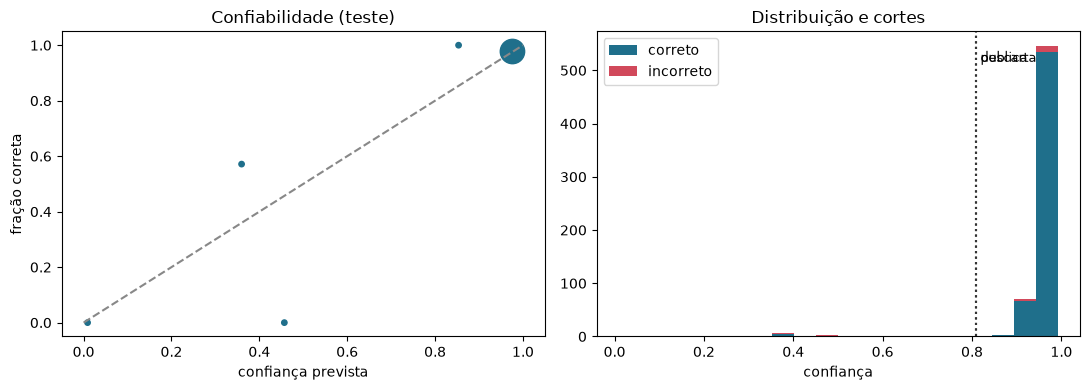

In [18]:
p_oof, y_oof = CAL.fora_da_amostra
X_t, y_t, _ = exemplos([ATIVA[s] for s in TESTE], ROT)
p_t = prob(CAL.pesos, X_t)
curva, ece = confiabilidade(p_t, y_t)
eces = []
for r in EXECS:
    X_r, y_r, _ = exemplos([r["ex"][s] for s in TESTE], r["rot"])
    eces.append(confiabilidade(prob(CAL.pesos, X_r), y_r)[1])
print(f"erro de calibração (ECE) no teste: média {np.mean(eces):.3f} (de {min(eces):.3f} a {max(eces):.3f}); gráfico da 1ª execução")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot([0, 1], [0, 1], ls="--", c="#888")
ax[0].scatter([c[0] for c in curva], [c[1] for c in curva], s=[max(15, c[2] / 2) for c in curva], c="#1f6f8b")
ax[0].set(xlabel="confiança prevista", ylabel="fração correta", title="Confiabilidade (teste)")
ax[1].hist([p_t[y_t == 1], p_t[y_t == 0]], bins=20, stacked=True, color=["#1f6f8b", "#d1495b"], label=["correto", "incorreto"])
for x, nome in ((CAL.corte_descartar, "descarta"), (CAL.corte_publicar, "publica")):
    ax[1].axvline(x, c="#333", ls=":")
    ax[1].text(x, ax[1].get_ylim()[1] * 0.9, f" {nome}", fontsize=9)
ax[1].set(xlabel="confiança", title="Distribuição e cortes"); ax[1].legend()
plt.tight_layout(); plt.show()
assert np.mean(eces) <= 0.05

## 7. Trocar de versão: calibrar a candidata e passar no gate

*Afirmação:* Uma versão candidata (outro prompt, modelo ou schema) muda a distribuição dos sinais, então roda 5 vezes e ajusta a própria calibração nas sentenças de calibração antes de ser comparada. Ativa e candidata são comparadas pelas 5 execuções de cada uma nas 200 de teste. Cada versão é medida pela soma das suas 5 execuções em cada sentença, e o *bootstrap* reamostra as sentenças, pareadas entre as versões: como cada sentença traz a média ruidosa das 5 execuções, o intervalo inclui a variação entre execuções. A candidata vira ativa se o limite inferior do IC 95% de ΔF1 for ≥ −3 pontos (não inferioridade; a margem é 2× a meia largura do intervalo que 200 sentenças e 5 execuções dão, para uma versão igual à ativa não ser reprovada por acaso) se o limite inferior do IC 95% da diferença na precisão da busca padrão (só *ratio*, o que o usuário vê quando pede os argumentos principais) for ≥ −1,5 ponto, com a margem derivada do mesmo jeito; e se o limite superior do IC 95% da taxa de inventados dela for ≤ 1,5%: critério absoluto, porque inventado é o erro que corrompe a base. A candidata C erra o papel (*obiter* rotulado como *ratio*): o F1 não vê, porque *obiter* correto conta como acerto, e só o critério da busca padrão a reprova.

A primeira linha é o teste A/A: a versão ativa em outras 5 execuções. Ela tem de passar, e o intervalo de ΔF1 tem de conter zero.

In [19]:
ATIVA_K = [r["cont"] for r in EXECS]
perfis = {
    "A/A: a versão ativa, outras 5 execuções": (PerfilSimulado(), 100),
    "candidata A (esquece menos, distorce menos)": (PerfilSimulado("cand_a", p_esquecido=0.03, p_distorce=0.02, p_parafrase=0.04), 200),
    "candidata B (verificador mais fraco)": (PerfilSimulado("cand_b", p_distorce=0.12, verificador_erro=0.06), 300),
    "candidata C (erra o papel: obiter como ratio)": (PerfilSimulado("cand_c", p_obiter_ratio=0.9, necessario_obiter=0.9), 400),
}
GATES = {}
for nome, (perfil, semente) in perfis.items():
    versao, _ = versao_extracao(f"perfil={perfil.nome}")
    runs, _ = rodar_versao(perfil, semente, versao)   # a candidata calibra na própria distribuição de sinais
    m = {k: np.mean([resumir(r["cont"])[k] for r in runs]) for k in ("f1", "inventados", "precisao_ratio")}
    GATES[nome] = g = gate(ATIVA_K, [r["cont"] for r in runs])
    print(f"{nome}\n  versão {versao} | F1 médio {M['f1']:.3f} → {m['f1']:.3f} | inventados {M['inventados']:.2%} → {m['inventados']:.2%}")
    print(f"  precisão da busca padrão {M['precisao_ratio']:.3f} → {m['precisao_ratio']:.3f}")
    print(f"  IC 95% ΔF1 [{g['ic_dif_f1'][0]:+.3f}, {g['ic_dif_f1'][1]:+.3f}] | IC 95% Δprecisão ratio [{g['ic_dif_precisao_ratio'][0]:+.3f}, {g['ic_dif_precisao_ratio'][1]:+.3f}]"
          f" | IC 95% inventados da candidata [{g['ic_inventados'][0]:.2%}, {g['ic_inventados'][1]:.2%}]")
    print(f"  critérios {g['criterios']} → {'APROVADA' if g['aprovada'] else 'REPROVADA'}")
aa = GATES["A/A: a versão ativa, outras 5 execuções"]
assert aa["aprovada"] and aa["ic_dif_f1"][0] < 0 < aa["ic_dif_f1"][1]
assert GATES["candidata A (esquece menos, distorce menos)"]["aprovada"]
assert not GATES["candidata B (verificador mais fraco)"]["aprovada"]
c_gate = GATES["candidata C (erra o papel: obiter como ratio)"]
assert c_gate["criterios"]["f1"] and not c_gate["criterios"]["precisao_ratio"] and not c_gate["aprovada"]

A/A: a versão ativa, outras 5 execuções
  versão ext_9884d198c5 | F1 médio 0.892 → 0.887 | inventados 0.19% → 0.10%
  precisão da busca padrão 0.964 → 0.964
  IC 95% ΔF1 [-0.021, +0.009] | IC 95% Δprecisão ratio [-0.007, +0.007] | IC 95% inventados da candidata [0.00%, 0.22%]
  critérios {'f1': True, 'precisao_ratio': True, 'inventados': True} → APROVADA


candidata A (esquece menos, distorce menos)
  versão ext_990aff1b46 | F1 médio 0.892 → 0.928 | inventados 0.19% → 0.06%
  precisão da busca padrão 0.964 → 0.968
  IC 95% ΔF1 [+0.023, +0.048] | IC 95% Δprecisão ratio [-0.002, +0.011] | IC 95% inventados da candidata [0.00%, 0.16%]
  critérios {'f1': True, 'precisao_ratio': True, 'inventados': True} → APROVADA


candidata B (verificador mais fraco)
  versão ext_71d6f01294 | F1 médio 0.892 → 0.832 | inventados 0.19% → 1.00%
  precisão da busca padrão 0.964 → 0.955
  IC 95% ΔF1 [-0.073, -0.046] | IC 95% Δprecisão ratio [-0.017, -0.001] | IC 95% inventados da candidata [0.68%, 1.33%]
  critérios {'f1': False, 'precisao_ratio': False, 'inventados': True} → REPROVADA


candidata C (erra o papel: obiter como ratio)
  versão ext_94273b4e10 | F1 médio 0.892 → 0.904 | inventados 0.19% → 0.31%
  precisão da busca padrão 0.964 → 0.951
  IC 95% ΔF1 [-0.000, +0.024] | IC 95% Δprecisão ratio [-0.020, -0.004] | IC 95% inventados da candidata [0.13%, 0.52%]
  critérios {'f1': True, 'precisao_ratio': False, 'inventados': True} → REPROVADA


## 8. Recalibrar não reextrai

*Afirmação:* `versao_extracao` cobre prompts, schema, todos os modelos (inclusive o árbitro e o NLI), o código, as constantes que ele lê e todas as regex do módulo; a calibração tem versão própria (`versao_decisao`). Como os sinais ficam gravados com cada argumento, mudar a regressão ou os cortes (aqui: exigir precisão esperada de 99% para publicar) reaplica a decisão sem nenhuma chamada ao LLM, e a chave de idempotência `(sentença, texto_hash, versao_extracao)` não muda.

In [20]:
import q2
antes = {a["id"]: a["status"] for e in ATIVA.values() for a in e.argumentos}
versao_decisao_antes = CAL.versao
cortes_98 = escolher_cortes(CAL.fora_da_amostra[0], precisao_alvo=0.99)   # publica só o conjunto com precisão esperada ≥ 99%
cal_98 = replace(CAL, corte_publicar=cortes_98[0], corte_descartar=cortes_98[1],
                 versao=sha256(json.dumps([CAL.versao, *cortes_98]))[:10])
contador = Contador(LLMSimulado(GABS))
aplicar_decisao(list(ATIVA.values()), cal_98)
mudaram = sum(antes[a["id"]] != a["status"] for e in ATIVA.values() for a in e.argumentos)
print(f"versão de extração {VERSAO_ATIVA} (igual) | decisão {versao_decisao_antes} → {cal_98.versao}")
print(f"corte de publicação {CAL.corte_publicar:.3f} → {cal_98.corte_publicar:.3f}: {mudaram} argumentos mudaram de status, {contador.n} chamadas ao LLM")
assert contador.n == 0 and mudaram > 0 and cal_98.versao != versao_decisao_antes
_ = aplicar_decisao(list(ATIVA.values()), CAL)   # volta à decisão ativa

for nome, valor in (("MODELO_NLI", "outro/nli-multilingue"), ("MODELO_VERIFICADOR_FORTE", "claude-opus-5-5"), ("LIMIAR_NLI", 0.6), ("PRECISAO_ALVO", 0.9)):
    original = getattr(q2, nome)
    setattr(q2, nome, valor)
    muda = q2.versao_extracao("perfil=ativa")[0] != VERSAO_ATIVA
    setattr(q2, nome, original)
    print(f"trocar {nome:<25} muda versao_extracao? {muda}")
    assert muda == (nome != "PRECISAO_ALVO"), "o que muda a extração muda a versão; o corte da decisão não"

versão de extração ext_9884d198c5 (igual) | decisão cc103496d3 → 0e7696a21c
corte de publicação 0.810 → 0.983: 870 argumentos mudaram de status, 0 chamadas ao LLM
trocar MODELO_NLI                muda versao_extracao? True
trocar MODELO_VERIFICADOR_FORTE  muda versao_extracao? True
trocar LIMIAR_NLI                muda versao_extracao? True
trocar PRECISAO_ALVO             muda versao_extracao? False


## 9. Revisão humana e versionamento

*Afirmação:* A extração é imutável; a revisão é uma tabela de eventos só com inserção, e a base consulta a visão `argumento_atual`. Uma edição é reverificada (referência que não está no trecho gera aviso). Dois revisores não sobrescrevem um ao outro (trava otimista). Numa reextração com outra versão, a linhagem liga o mesmo argumento entre execuções, um para um (algoritmo húngaro: dois argumentos novos nunca herdam a mesma linhagem): aprovado ou editado continua valendo; rejeitado por "não está no texto", "argumento da parte", "duplicado" ou "irrelevante" é suprimido; rejeitado por "resumo distorce" ou "obiter" volta para revisão, porque a nova extração pode ter corrigido; o que o humano adicionou fica. Depois de embargos de declaração o texto muda e os offsets andam: os trechos antigos são reancorados no texto novo antes de comparar, e a aprovação humana continua valendo com as posições novas.

In [21]:
base = Base()
sid = next(s for s in TESTE if GABS[s].natureza == "merito" and len(GABS[s].argumentos) >= 7)   # sentença de mérito, com argumentos para revisar
e1 = base.processar(sid, PDFS[sid], LLMSimulado(GABS, seed=11), VERSAO_ATIVA)
aplicar_decisao([e1], CAL)
base.gravar(e1)
args = sorted(base.argumento_atual(sid), key=lambda a: a["trechos"][0]["paragrafo"])
for a in args:
    print(f"{a['id']}  {a['linhagem_id']}  §{a['trechos'][0]['paragrafo']:<3} {a['tipo']:<22} {a['status']:<11} {a['tese'][:50]}")

arg_b6ead9  lin_0f1271  §15  preliminar_processual  publicado   Responde pela inscrição em cadastro de inadimplent
arg_20e44c  lin_a482e3  §19  onus_prova             publicado   Na relação de consumo, inverte-se o ônus da prova 
arg_848a62  lin_351309  §21  merito_direito         publicado   A inscrição decorrente de débito inexistente deve 
arg_ec4042  lin_6be82e  §23  merito_direito         publicado   Inscrições anteriores já canceladas não atraem a S
arg_e330c4  lin_9befbf  §26  quantificacao          publicado   O dano moral é fixado pela extensão do dano, pela 
arg_46a1ec  lin_9bddaf  §27  quantificacao          publicado   Na responsabilidade extracontratual, os juros de m


In [22]:
publicados = [a for a in args if a["status"] == "publicado"]
a_ok, a_edit, a_dist = publicados[:3]
a_parte = next((a for a in args if a["sinais"]["marcador_alegacao"] or a["sinais"]["postura"] == "relata"), publicados[3])
print(f"rejeitar como argumento da parte: {a_parte['id']} §{a_parte['trechos'][0]['paragrafo']}: {a_parte['trechos'][0]['texto'][:70]}")
print("aceitar:", base.revisar(a_ok["id"], "adv_1", "aceitar", versao_esperada=0))
avisos = base.revisar(a_edit["id"], "adv_1", "editar", versao_esperada=0,
                      campos={"resumo": a_edit["resumo"] + " (revisado)", "precedentes": a_edit["precedentes"] + [{"tribunal": "STJ", "tipo": "resp", "numero": "1"}]})
print("editar com precedente que não está no trecho → avisos:", avisos)
assert avisos
base.revisar(a_dist["id"], "adv_2", "rejeitar", versao_esperada=0, motivo="resumo_distorce")
base.revisar(a_parte["id"], "adv_2", "rejeitar", versao_esperada=0, motivo="argumento_da_parte")
try:
    base.revisar(a_ok["id"], "adv_2", "rejeitar", versao_esperada=0, motivo="irrelevante")   # a tela do adv_2 abriu antes do aceite
except ConflitoDeRevisao as erro:
    print("conflito:", erro)
fund = [p for p in base.sentencas[sid].da_secao("fundamentacao") if not p.titulo]
p_h = fund[-1]
novo = base.adicionar(sid, "adv_1", (p_h.char_ini, p_h.char_ini + 80), tese="A sentença conclui o tópico com o fundamento do revisor",
                      resumo="O juiz conclui o tópico.", tipo="merito_direito", papel="ratio_decidendi", pedidos=["P1"],
                      conclusao="acolhe", favorece="autor")
print("adicionado:", novo, "| trecho:", json.loads(base.args[novo])["trechos"][0]["texto"][:60])
print("eventos:", [(ev["acao"], ev["motivo"]) for ev in base.eventos])

rejeitar como argumento da parte: arg_ec4042 §23: As inscrições anteriores apontadas pelo réu foram canceladas antes des
aceitar: []
editar com precedente que não está no trecho → avisos: ["precedente {'tribunal': 'STJ', 'tipo': 'resp', 'numero': '1'} não está escrito no §19"]
conflito: lin_0f1271: outra revisão foi gravada depois que esta tela abriu
adicionado: arg_hb2269 | trecho: Considerando a extensão do dano, a capacidade econômica das 
eventos: [('aceitar', None), ('editar', None), ('rejeitar', 'resumo_distorce'), ('rejeitar', 'argumento_da_parte'), ('adicionar', None)]


In [23]:
versao_nova, _ = versao_extracao("perfil=cand_a")
chamadas_antes = base.chamadas_llm
base.processar(sid, PDFS[sid], LLMSimulado(GABS, seed=11), VERSAO_ATIVA)
print("mesma versão de novo → chamadas ao LLM:", base.chamadas_llm - chamadas_antes, "(idempotente)")
assert base.chamadas_llm == chamadas_antes
e2 = base.processar(sid, PDFS[sid], LLMSimulado(GABS, perfis["candidata A (esquece menos, distorce menos)"][0], seed=12), versao_nova)
aplicar_decisao([e2], CAL)
base.gravar(e2)
print(f"run ativo: {base.ativo[sid]} (versão {versao_nova}); run anterior {e1.run_id} continua consultável: {e1.run_id in base.runs}\n")
atual = {a["linhagem_id"]: a for a in base.argumento_atual(sid)}
for nome, a in (("aceito", a_ok), ("editado", a_edit), ("rejeitado: resumo_distorce", a_dist), ("rejeitado: argumento_da_parte", a_parte)):
    n = atual.get(a["linhagem_id"])
    print(f"{nome:<30} → {n['status'] if n else '(não reapareceu na nova extração)':<12} {n.get('rejeicao_anterior', '') if n else ''}")
assert atual[a_ok["linhagem_id"]]["status"] == "aprovado"
assert atual[a_edit["linhagem_id"]]["status"] == "editado" and atual[a_edit["linhagem_id"]]["resumo"].endswith("(revisado)")
if a_dist["linhagem_id"] in atual:
    assert atual[a_dist["linhagem_id"]]["status"] == "em_revisao"
if a_parte["linhagem_id"] in atual:
    assert atual[a_parte["linhagem_id"]]["status"] == "suprimido"
assert any(a.get("origem") == "humano" for a in atual.values())
linhagens_e2 = [json.loads(base.args[i])["linhagem_id"] for i in base.runs[base.ativo[sid]]["args"]]
assert len(linhagens_e2) == len(set(linhagens_e2)), "cada linhagem tem no máximo um argumento por execução"

mesma versão de novo → chamadas ao LLM: 0 (idempotente)
run ativo: run_92f59a6a (versão ext_990aff1b46); run anterior run_cf863ae5 continua consultável: True

aceito                         → aprovado     
editado                        → editado      
rejeitado: resumo_distorce     → em_revisao   resumo_distorce
rejeitado: argumento_da_parte  → suprimido    


In [24]:
pdf_emb, gab_emb = gerar_sentenca(int(sid.split("_")[1]), embargos=True)   # a mesma sentença, integrada pelos embargos (um parágrafo a mais)
e3 = base.processar(sid, pdf_emb, LLMSimulado({sid: gab_emb}, seed=13), VERSAO_ATIVA)
aplicar_decisao([e3], CAL)
base.gravar(e3)
print(f"texto_hash {e2.texto_hash} → {e3.texto_hash}")
depois = {a["linhagem_id"]: a for a in base.argumento_atual(sid)}
n_ok = depois[a_ok["linhagem_id"]]
t_antes, t_depois = atual[a_ok["linhagem_id"]]["trechos"][0], n_ok["trechos"][0]
print(f"aprovado antes dos embargos: §{t_antes['paragrafo']} offset {t_antes['char_ini']} → depois: {n_ok['status']}, §{t_depois['paragrafo']} offset {t_depois['char_ini']}")
assert n_ok["status"] == "aprovado" and t_depois["char_ini"] != t_antes["char_ini"]
assert base.sentencas[sid].texto[t_depois["char_ini"]:t_depois["char_fim"]] == t_depois["texto"], "a posição nova aponta para o mesmo texto"
print("retângulos do trecho no PDF novo (pt):", t_depois["retangulos"][:2])

texto_hash 7eae755442c3a682 → cd32345e402ac8f3
aprovado antes dos embargos: §15 offset 1181 → depois: aprovado, §16 offset 1359
retângulos do trecho no PDF novo (pt): [[60.0, 634.1, 274.6, 649.2]]


## 10. Custo por sentença

*Afirmação:* Por sentença de mérito: 1 chamada de mapa e 1 segunda leitura do dispositivo (Haiku), uma de extração por tópico (Sonnet, prefixo em cache, mais as reextrações e as dirigidas), uma de verificação por argumento (Haiku) e a arbitragem (Sonnet) quando o verificador e o NLI discordam ou o verificador fica em "parcial". A homologatória custa só o mapa; a terminativa, o mapa e uma ou duas extrações curtas. O custo médio é ponderado pela proporção real das naturezas (seção 12), não pela do conjunto de teste, que sobreamostra o mérito. O custo é tokens × preço vigente de cada modelo; o preço não fica escrito no código.


In [25]:
por_natureza = defaultdict(list)
for s, e in ATIVA.items():
    por_natureza[GABS[s].natureza].append(e)
PROPORCAO_REAL = {"merito": 77 / 226, "terminativa": 112 / 226, "homologatoria": 37 / 226}   # contada na seção 12
campos = ("chamadas", "entrada", "cache_escrita", "cache_leitura", "saida")
ponderado = defaultdict(Counter)
for natureza, execs_n in sorted(por_natureza.items()):
    custo = custo_por_sentenca(execs_n)
    print(f"{natureza} ({len(execs_n)} sentenças, {PROPORCAO_REAL[natureza]:.0%} do corpus real)")
    print(f"  {'papel':<18}{'chamadas':>9}{'entrada':>9}{'cache escr.':>12}{'cache leit.':>12}{'saída':>8}")
    for papel, t in custo.items():
        print(f"  {papel:<18}{t['chamadas']:>9}{t['entrada']:>9}{t['cache_escrita']:>12}{t['cache_leitura']:>12}{t['saida']:>8}")
        for k in campos:
            ponderado[papel][k] += PROPORCAO_REAL[natureza] * t[k]
print("\nmédia ponderada pela proporção real")
for papel, t in ponderado.items():
    print(f"  {papel:<18}{t['chamadas']:>9.1f}{t['entrada']:>9.0f}{t['cache_escrita']:>12.0f}{t['cache_leitura']:>12.0f}{t['saida']:>8.0f}")
extr = custo_por_sentenca(por_natureza["merito"])["extrator"]
print(f"\nno extrator, nas sentenças de mérito, {extr['cache_leitura'] / (extr['entrada'] + extr['cache_escrita'] + extr['cache_leitura']):.0%} dos tokens de entrada são leitura de cache")
assert custo_por_sentenca(por_natureza["homologatoria"]) .keys() == {"mapa"}


homologatoria (48 sentenças, 16% do corpus real)
  papel              chamadas  entrada cache escr. cache leit.   saída
  mapa                    1.0   1211.8         0.0         0.0    68.6
merito (206 sentenças, 34% do corpus real)
  papel              chamadas  entrada cache escr. cache leit.   saída
  mapa                    1.0   1694.8         0.0         0.0   278.4
  dispositivo             1.0    768.8         0.0         0.0     9.4
  extrator                4.1    840.5      1537.0      5117.0  1158.1
  verificador             5.5   3846.1         0.0         0.0   143.2
  verificador_forte       0.9    655.8         0.0         0.0    24.2
  resultado               0.0     29.6         0.0         0.0     2.2
terminativa (46 sentenças, 50% do corpus real)
  papel              chamadas  entrada cache escr. cache leit.   saída
  mapa                    1.0   1233.6         0.0         0.0   128.2
  extrator                2.3    509.2      1257.0      1645.9   366.9
  verific

## 11. A base: questões, posições, valores e dados sensíveis

*Afirmação:* Cada argumento traz a `questao` jurídica que responde, neutra (a mesma pergunta para quem decide a favor e contra), a `tese` (a posição que o juiz toma, em termos gerais) e um `resumo` de como o juiz a aplicou. As razões de decidir dos tipos de direito, de sentenças sem segredo nem dado sensível, são agrupadas pela questão, e cada questão guarda o placar dos dois lados. Agrupar pela tese juntaria posições opostas (um embedding denso separa mal "afasta" de "não afasta") ou partiria a questão sem mostrar o placar. O tipo não entra na comparação (um tipo errado partiria a mesma questão em duas). Valores saem do trecho conferido, em centavos, e é por eles que a quantificação se agrega. Dado sensível (art. 11 da LGPD) é detectado por dicionário e regex. Aqui o cosseno entre questões é o do substituto léxico do BGE-M3.


In [26]:
base_t = Base()
for s in IDS:
    base_t.gravar(ATIVA[s])
por_questao = defaultdict(list)
for s in IDS:
    casados = casar_com_gabarito(ATIVA[s], GABS[s], ATIVA[s].argumentos)
    for i in base_t.runs[base_t.ativo[s]]["args"]:
        a = json.loads(base_t.args[i])
        if a["questao_id"]:
            por_questao[a["questao_id"]].append(casados[a["id"]].questao if a["id"] in casados else None)
pares = sum(len(v) * (len(v) - 1) / 2 for v in por_questao.values())
certos = sum(c * (c - 1) / 2 for v in por_questao.values() for t, c in Counter(v).items() if t is not None)   # sem gabarito conta como erro
QS = base_t.questoes.questoes
print(f"{len(QS)} questões, {sum(len(v) for v in por_questao.values())} argumentos | precisão de pares na mesma questão: {certos / pares:.3f}")
for qid, q in sorted(QS.items(), key=lambda x: -x[1]["n"])[:7]:
    print(f"  {q['n']:>4}  {q['texto'][:90]}  | placar {dict(q['placar'])}")
assert certos / pares >= 0.90
sumula = next(q for q in QS.values() if "Súmula 385" in q["texto"])
print("\nas duas posições sobre a Súmula 385, na mesma questão:")
for (lado, tese), n in sumula["teses"].most_common():
    print(f"  {n:>4}  a favor de {lado:<6} {tese[:90]}")
assert {"autor", "reu"} <= set(sumula["placar"]), "a questão guarda os dois lados"

valores = defaultdict(list)   # "quanto se fixa de dano moral": decisões procedentes de dano moral, pelo valor conferido
for s in IDS:
    e = ATIVA[s]
    danos_morais = {p.id for p in e.mapa.pedidos if "moral" in p.texto} if e.mapa else set()
    for d in e.decisoes:
        if d["pedido"] in danos_morais and d["valor_centavos"]:
            valores[GABS[s].area].append(d["valor_centavos"] / 100)
for area, v in valores.items():
    print(f"dano moral fixado ({area}): n={len(v)}, mediana R$ {np.median(v):,.0f}, de R$ {min(v):,.0f} a R$ {max(v):,.0f}")

print("\ndado sensível:", dados_sensiveis("A autora, gestante, juntou laudo médico com CID F32."), "| sentenças sintéticas com dado sensível:",
      sum(bool(dados_sensiveis(e.sentenca.texto)) for e in ATIVA.values()))
assert dados_sensiveis("A autora, gestante, juntou laudo médico com CID F32.") == ["saude"]

16 questões, 516 argumentos | precisão de pares na mesma questão: 0.993
    80  A readequação da malha aérea afasta a responsabilidade da transportadora pelo atraso?  | placar {'autor': 78, 'reu': 2}
    77  O atraso de voo gera dano moral?  | placar {'reu': 36, 'autor': 41}
    74  Cabe inverter o ônus da prova do fato negativo alegado pelo consumidor?  | placar {'autor': 73, 'reu': 1}
    69  A inscrição decorrente de débito inexistente deve ser excluída?  | placar {'autor': 69}
    58  Inscrições anteriores do consumidor em cadastro de inadimplentes afastam o dano moral pela  | placar {'autor': 34, 'reu': 24}
    40  Qual o prazo de prescrição da pretensão indenizatória por atraso de voo internacional (Con  | placar {'autor': 39, 'reu': 1}
    35  Quem requereu a inscrição em cadastro de inadimplentes tem legitimidade passiva para respo  | placar {'autor': 35}

as duas posições sobre a Súmula 385, na mesma questão:
    34  a favor de autor  Inscrições anteriores já canceladas não at

## 12. A parte determinística em 226 sentenças reais

*Afirmação:* Sobre texto real (226 sentenças públicas do Juizado Especial Cível do TJSP, 1º semestre de 2024, pseudonimizadas; as mesmas da Q1), sem LLM e sem custo: a regex acha as duas fronteiras em todas, e as fronteiras de 25 sentenças conferidas à mão batem com as esperadas. A natureza sai do comando do dispositivo: a maior parte do Juizado não é sentença de mérito, e o desenho trata cada natureza de um jeito (seção 4). Nenhuma tem título de tópico: a fundamentação inteira é uma unidade de extração. No texto exportado do e-SAJ, o parágrafo do juiz e a ementa que ele transcreve vêm na mesma linha: a citação entre aspas dentro do parágrafo é marcada no trecho, e um trecho que cai dentro dela não é argumento do juiz. Contam-se também citações marcadas, marcadores de *obiter* e de alegação da parte, referências normativas e dados sensíveis.


In [27]:
REAIS = json.load(open("sentencas_tjsp.json"))["sentencas"]
reais = []
for i, s in enumerate(REAIS):
    st = ler_texto(f"tjsp_{i:03d}", s["texto"])
    marcar_citacoes(st)
    r = fronteiras_regex(st)
    if None not in (r["fundamentacao"], r["dispositivo"]):
        segmentar(st, r)
    st.natureza = r["natureza"]
    reais.append((st, r))
achadas = sum(None not in (r["fundamentacao"], r["dispositivo"]) for _, r in reais)
naturezas = Counter(st.natureza for st, _ in reais)
print(f"fronteiras achadas pela regex: {achadas}/{len(reais)} | naturezas: " + ", ".join(f"{n} {k} ({k / len(reais):.0%})" for n, k in naturezas.most_common()))
for natureza in ("merito", "terminativa", "homologatoria"):
    tokens = [estimar_tokens(st.texto) for st, _ in reais if st.natureza == natureza]
    print(f"  {natureza:<14} tokens: mediana {int(np.median(tokens)):>5}, máximo {max(tokens):>5}")
assert achadas == len(reais) and set(naturezas) == {"merito", "terminativa", "homologatoria"}

CONFERIDAS = {0: (10, 36, "merito"), 26: (6, 9, "terminativa"), 30: (12, 31, "merito"), 57: (11, 11, "homologatoria"), 61: (12, 27, "merito"),
              81: (10, 10, "homologatoria"), 107: (10, 16, "terminativa"), 112: (8, 8, "terminativa"), 125: (10, 21, "terminativa"),
              128: (9, 12, "terminativa"), 131: (11, 19, "terminativa"), 140: (8, 9, "terminativa"), 142: (8, 11, "terminativa"),
              146: (10, 16, "terminativa"), 150: (10, 32, "merito"), 153: (8, 9, "terminativa"), 159: (8, 11, "terminativa"),
              165: (8, 8, "homologatoria"), 187: (10, 26, "merito"), 192: (8, 8, "terminativa"), 196: (8, 11, "terminativa"),
              197: (8, 12, "terminativa"), 198: (8, 12, "terminativa"), 200: (8, 11, "terminativa"), 220: (9, 12, "terminativa")}   # lidas à mão
erradas = {i: (reais[i][1]["fundamentacao"], reais[i][1]["dispositivo"], reais[i][1]["natureza"]) for i in CONFERIDAS
           if (reais[i][1]["fundamentacao"], reais[i][1]["dispositivo"], reais[i][1]["natureza"]) != CONFERIDAS[i]}
print(f"conferência manual: {len(CONFERIDAS) - len(erradas)}/{len(CONFERIDAS)} com fundamentação, dispositivo e natureza certos")
assert not erradas
for i in (94, 151, 139):   # mérito, terminativa, homologatória
    st, r = reais[i]
    print(f"\ntjsp_{i:03d} ({st.natureza}): fundamentação §{r['fundamentacao']} «{st.par(r['fundamentacao']).texto[:70]}…»")
    print(f"           dispositivo §{r['dispositivo']} «{st.par(r['dispositivo']).texto[:70]}…»")

fronteiras achadas pela regex: 226/226 | naturezas: terminativa 112 (50%), merito 77 (34%), homologatoria 37 (16%)
  merito         tokens: mediana  2349, máximo  4830
  terminativa    tokens: mediana  1055, máximo  3191
  homologatoria  tokens: mediana   439, máximo   539
conferência manual: 25/25 com fundamentação, dispositivo e natureza certos

tjsp_094 (merito): fundamentação §12 «A parte autora objetiva a condenação do requerido à restituição da qua…»
           dispositivo §29 «Ante o exposto, JULGO PARCIALMENTE PROCEDENTES os pedidos iniciais e e…»

tjsp_151 (terminativa): fundamentação §8 «Nos termos do artigo 51, I, da Lei 9.099/95, o processo será extinto, …»
           dispositivo §11 «Ante o exposto, JULGO EXTINTO o processo, sem o julgamento do mérito. …»

tjsp_139 (homologatoria): fundamentação §8 «HOMOLOGO, por sentença, para que produza seus jurídicos e legais efeit…»
           dispositivo §8 «HOMOLOGO, por sentença, para que produza seus jurídicos e legais efeit…»


In [28]:
merito = [st for st, _ in reais if st.natureza == "merito"]
fund = [p for st in merito for p in st.da_secao("fundamentacao")]
titulos = sum(p.titulo for p in fund)
citacoes = [p for p in fund if p.e_citacao]
obiter_r = [p for p in fund if marcador_obiter(p.texto)]
alegacao_r = [p for p in fund if marcador_alegacao(p.texto)]
normas_r = Counter(r["norma"] for p in fund for r in referencias(p.texto)[0])
precedentes_r = Counter(f"{r['tipo']} {r['tribunal']}" for p in fund for r in referencias(p.texto)[1])
print(f"{len(merito)} sentenças de mérito, {len(fund)} parágrafos de fundamentação | títulos de tópico: {titulos} | citações marcadas: {len(citacoes)}")
print("normas mais citadas:", normas_r.most_common(6))
print("precedentes:", precedentes_r.most_common(4))
print(f"\nmarcador de obiter em {len(obiter_r)} parágrafos:")
for p in obiter_r[:3]:
    print("  ", p.texto[:120])
print(f"marcador de alegação da parte em {len(alegacao_r)} parágrafos (sinal, não descarte: o juiz recita para rebater):")
for p in alegacao_r[:3]:
    print("  ", p.texto[:120])
print("\nsentenças com dado sensível (fora das questões agrupadas):", Counter(c for st, _ in reais for c in dados_sensiveis(st.texto)))
assert titulos == 0

st0 = reais[0][0]
mapa0 = RespostaMapa(processo=None, juiz=None, partes=[], segredo_de_justica=False, natureza="merito", inicio_fundamentacao=None,
                     inicio_dispositivo=None, pedidos=[], decisoes=[], fatos_provados=[])
juiz = "à parte autora incumbe o ônus de evidenciar minimamente os fatos constitutivos do seu direito"
stj = "a inversão do ônus da prova não dispensa a comprovação mínima, pela parte autora, dos fatos constitutivos do seu direito"
print(f"\ntjsp_000 §17: {st0.par(17).texto[:150]}…")
for nome, citacao in (("frase do juiz", juiz), ("frase do STJ, entre aspas", stj)):
    c = ArgumentoCandidato(questao="A inversão do ônus da prova dispensa a prova mínima dos fatos constitutivos?", tese="A inversão do ônus não dispensa a prova mínima",
                           resumo="O juiz exige da parte autora a prova mínima dos fatos.", tipo="onus_prova", por_que_papel="(exemplo)", papel="ratio_decidendi",
                           pedidos=[], conclusao="rejeita", favorece="reu", paragrafos=[17], citacao_literal=citacao, normas=[], precedentes=["AgInt no REsp 1717781/RO"])
    arg, motivo = verificar_candidato(st0, mapa0, c)
    print(f"  {nome:<26} → {'ACEITO, precedente ' + str(arg['precedentes']) if arg else 'DESCARTADO: ' + motivo}")
    assert (arg is not None) == (nome == "frase do juiz")

77 sentenças de mérito, 1356 parágrafos de fundamentação | títulos de tópico: 0 | citações marcadas: 57
normas mais citadas: [('CPC', 124), ('CDC', 120), ('CC', 15), ('Lei 9.099/95', 12), ('CF', 5)]
precedentes: [('agint_no_resp STJ', 23), ('sumula STJ', 13), ('sumula ?', 11), ('resp STJ', 11)]

marcador de obiter em 1 parágrafos:
   Ainda que assim não fosse, o ordenamento jurídico brasileiro adota a teoria do risco (Código Civil, art. 927, parágrafo 
marcador de alegação da parte em 14 parágrafos (sinal, não descarte: o juiz recita para rebater):
   A requerente, em suma, aduz que a parte ré veicula em seu sítio eletrônico a possibilidade de consecução de bolsa integr
   O autor alega, em apertada síntese, que é taxista e trafegava pela Hugo Barros Bastos e na altura do número 1226, quando
   Alega o autor que contratou os serviços do requerido para desentupimento do encanamento de esgoto utilizando o maquinári



sentenças com dado sensível (fora das questões agrupadas): Counter({'saude': 18})

tjsp_000 §17: Ainda assim, à parte autora incumbe o ônus de evidenciar minimamente os fatos constitutivos do seu direito, na forma do art. 373, inc. I, do Código de…
  frase do juiz              → ACEITO, precedente [{'numero': '1717781', 'tipo': 'agint_no_resp', 'tribunal': 'STJ'}]
  frase do STJ, entre aspas  → DESCARTADO: seção: o trecho está entre aspas no §17: é citação dentro do parágrafo do juiz
